# v2 – log(wind speed) as input

The third model version. It keeps everything of [v1](v1_tau.ipynb) (data, split, target log(τ), models) and changes only how the wind speed enters the models.

![Flow of v2_log_wind](images/v2_log_wind_flow.png)

**How to read it:** grey is the data, blue the training on the training cases, orange the prediction and the scores on the test cases. The two vertical arrows are what training hands over to the prediction: the fitted scaling and categories, and the fitted models. Steps with a thick border and a tag are new in this version.

| | v1 | v2 |
|---|---|---|
| Inputs | 10 setup values, wind speed in m/s | the same, but the wind speed as log(wind speed) |
| Model target | log(`tau_s`) | the same |
| t90 | t90 = ln(10) · τ | the same |
| Models | mean value, LinearRegression, Ridge, DecisionTree | the same, with the same parameters |

Why: τ scales with about 1 / wind speed (v0, section 9). Between log(τ) and the wind speed this is a curve, between log(τ) and log(wind speed) a straight line, which a linear model can represent exactly.

The column meanings are in [results/README.md](../results/README.md).

## 1) Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

VERSION = "v2_log_wind"
RANDOM_STATE = 42
LN10 = np.log(10)  # t90 = ln(10) * tau, see section 3

DATA_PATH = Path("../results/dataset_550/dataset_550.csv")
RESULTS_DIR = Path("results")
print("Data file:", DATA_PATH, "| found:", DATA_PATH.exists())

Data file: ../results/dataset_550/dataset_550.csv | found: True


## 2) Load the data

Only rows with `status = ok` are used. The 9 `failed` rows have no results (a numerical fault in the simulation; they will be rerun).

`case_id` becomes the index, so every prediction can be traced back to its simulation.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df[df["status"] == "ok"].set_index("case_id")

TARGET_COL = "t90_s"
# Only values that are fixed before a simulation starts (same choice as in unit 2)
FEATURE_COLS = [
    "layout",
    "window1_x_m",
    "window1_mode",
    "window1_angle_deg",
    "window1_hinge",
    "window2_x_m",
    "window2_mode",
    "window2_angle_deg",
    "window2_hinge",
    "wind_speed_ms",
]

print("Simulations:", len(df))
print("Missing input values:", int(df[FEATURE_COLS].isna().sum().sum()))

t90_reached = df[TARGET_COL].notna()
display(pd.crosstab(
    df["layout"],
    t90_reached.map({True: "t90 reached", False: "t90 > 600 s"}),
    margins=True,
    margins_name="total",
))

Simulations: 541
Missing input values: 0


t90_s,t90 > 600 s,t90 reached,total
layout,,,
adjacent_walls,22,228,250
opposite_walls,20,230,250
same_wall,34,7,41
total,76,465,541


Most same-wall cases (both windows in the wind-facing wall) do not reach 90 % within the 10 simulated minutes, so they have no `t90_s`.

## 3) Train/test split – the same in every version

- 80 % of the simulations for training, 20 % for testing, `random_state = 42`.
- Stratified by layout **and** by whether t90 is reached. Same-wall cases are rare (41) and mostly do not reach t90; without this, the test set got only 5 of them.
- The split is made on all `ok` cases, before anything is left out. **Every later version uses exactly this code**, so all versions are tested on the same simulations. Changing it makes the versions incomparable.
- The separate test run `test-v1` (30 new simulations) will be the final test once it has run. Until then, this split is used to compare the versions.

In [3]:
strata = df["layout"] + " / " + np.where(t90_reached, "reached", "not reached")

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=strata,
)

print("Training simulations:", len(train_df))
print("Test simulations:    ", len(test_df))
display(pd.crosstab(test_df["layout"], test_df[TARGET_COL].notna().map({True: "t90 reached", False: "t90 > 600 s"})))

Training simulations: 432
Test simulations:     109


t90_s,t90 > 600 s,t90 reached
layout,,
adjacent_walls,5,46
opposite_walls,4,46
same_wall,7,1


### As in v1: the target is log(τ), for every case

`tau_s` (τ) is the time constant of the air-replacement curve, fresh_fraction ≈ 1 − exp(−t / τ). It is defined for every simulation, also when 90 % are not reached within 600 s. v1 therefore trains on all training cases, including the 33 same-wall cases (v0: 6).

The model learns **log(τ)** instead of τ:

- τ = exp(prediction) is always positive, so there are no negative times.
- τ scales roughly with 1 / wind speed. In log space such factors become sums, which suits a linear model.
- An error of a factor of 2 counts the same for a fast and for a slow case.

t90 follows from the curve shape: 1 − exp(−t90 / τ) = 0.9 gives **t90 = ln(10) · τ ≈ 2.30 · τ**.

In [4]:
TAU_COL = "tau_s"

X_train, y_train = train_df[FEATURE_COLS], np.log(train_df[TAU_COL])
X_test = test_df[FEATURE_COLS]

print("Training:", X_train.shape, "| Test:", X_test.shape)
display(pd.DataFrame({
    "train": train_df["layout"].value_counts(),
    "test": test_df["layout"].value_counts(),
}))

Training: (432, 10) | Test: (109, 10)


,train,test
layout,,
adjacent_walls,199,51
opposite_walls,200,50
same_wall,33,8


**How exact is t90 = ln(10) · τ?** The simulated curves are not exactly exponential. The check uses the training cases that have both values:

In [5]:
both = train_df[train_df[TARGET_COL].notna()]
ratio = both[TARGET_COL] / both[TAU_COL]
conversion_error = mean_absolute_error(both[TARGET_COL], LN10 * both[TAU_COL])

print(f"t90 / τ: mean {ratio.mean():.3f}, from {ratio.min():.2f} to {ratio.max():.2f} (ln 10 = {LN10:.3f})")
print(f"t90 from the simulated τ: MAE {conversion_error:.1f} s")

t90 / τ: mean 2.334, from 2.03 to 2.65 (ln 10 = 2.303)
t90 from the simulated τ: MAE 5.0 s


Even a perfect τ model would miss t90 by only a few seconds on average. Larger errors come from predicting τ, not from the conversion.

## 4) Preprocessing – new in v2: log(wind speed)

The wind speed now passes two steps: `FunctionTransformer(np.log)` takes its logarithm, then `StandardScaler` standardises it like the other numeric inputs. The other inputs are treated as in v0 and v1.

Because the logarithm is a step of the pipeline, it is also applied automatically to new data in `predict`. The wind speed is always between 1 and 5 m/s, so the logarithm is always defined.

In [6]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [col for col in FEATURE_COLS if col not in num_cols]
WIND_COL = "wind_speed_ms"
other_num_cols = [col for col in num_cols if col != WIND_COL]


def build_preprocessor():
    log_wind = Pipeline(steps=[
        ("log", FunctionTransformer(np.log, feature_names_out=lambda transformer, names: ["log_wind_speed"])),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        transformers=[
            ("wind", log_wind, [WIND_COL]),
            ("num", StandardScaler(), other_num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


print("log(wind speed):        ", [WIND_COL])
print("Other numeric inputs:   ", other_num_cols)
print("Categorical inputs:     ", cat_cols)

log(wind speed):         ['wind_speed_ms']
Other numeric inputs:    ['window1_x_m', 'window1_angle_deg', 'window2_x_m', 'window2_angle_deg']
Categorical inputs:      ['layout', 'window1_mode', 'window1_hinge', 'window2_mode', 'window2_hinge']


## 5) Models as pipelines

The same pipelines and parameters as in v0 and v1, fitted on log(τ) as in v1. Only the preprocessing step differs (section 4).

In [7]:
models = {
    "Mean value (reference)": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "DecisionTree": DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE),
}

pipelines = {}
tau_pred = pd.DataFrame(index=X_test.index)
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocess", build_preprocessor()),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline
    tau_pred[name] = np.exp(pipeline.predict(X_test))  # log(τ) -> τ in seconds

t90_pred = LN10 * tau_pred

display(pd.concat([test_df[[TAU_COL, TARGET_COL]], tau_pred.add_prefix("τ ")], axis=1).head().round(0))

,tau_s,t90_s,τ Mean value (reference),τ LinearRegression,τ Ridge,τ DecisionTree
case_id,,,,,,
train-a-v2_092,77.0,187.0,99.0,79.0,81.0,78.0
train-a-v2_136,75.0,173.0,99.0,60.0,62.0,103.0
train-v1_074,28.0,64.0,99.0,32.0,32.0,29.0
train-v1_095,199.0,458.0,99.0,168.0,169.0,208.0
train-v1_080,23.0,50.0,99.0,41.0,42.0,45.0


## 6) Evaluation on the test cases

### 6.1 t90, compared with v0 and v1

The same scores as in v0 (MAE, RMSE, R²; see v0 section 6) on the same 93 test cases: those of the shared split that have a t90 value.

In [8]:
def scores(y_true, y_pred):
    return {
        "MAE [s]": mean_absolute_error(y_true, y_pred),
        "RMSE [s]": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
        "lowest prediction [s]": np.min(y_pred),
    }


has_t90 = test_df[TARGET_COL].notna()
y_test_t90 = test_df.loc[has_t90, TARGET_COL]
results = pd.DataFrame({name: scores(y_test_t90, t90_pred.loc[has_t90, name]) for name in t90_pred}).T
display(results.round(3))

earlier = {v: pd.read_csv(RESULTS_DIR / f"{v}.csv").set_index("model") for v in ["v0_base", "v1_tau"]}
comparison = {}
for score in ["MAE [s]", "R²"]:
    for v, label in [("v0_base", "v0"), ("v1_tau", "v1")]:
        comparison[f"{label} {score}"] = earlier[v][score]
    comparison[f"v2 {score}"] = results[score]
display(pd.DataFrame(comparison).round(3))

,MAE [s],RMSE [s],R²,lowest prediction [s]
Mean value (reference),115.568,142.251,-0.007,228.013
LinearRegression,47.322,71.622,0.745,51.048
Ridge,47.252,72.828,0.736,52.929
DecisionTree,57.922,85.315,0.638,65.723


,v0 MAE [s],v1 MAE [s],v2 MAE [s],v0 R²,v1 R²,v2 R²
Mean value (reference),114.969,115.568,115.568,-0.005,-0.007,-0.007
LinearRegression,53.050,50.206,47.322,0.753,0.713,0.745
Ridge,53.450,50.135,47.252,0.734,0.704,0.736
DecisionTree,42.081,57.922,57.922,0.806,0.638,0.638


### 6.2 Where the error changed

The mean absolute t90 error of v0, v1 and v2, split by the simulated t90. The `*_test_predictions.csv` files hold the predictions of v0 and v1 for the same test cases.

In [9]:
v0_pred = pd.read_csv(RESULTS_DIR / "v0_base_test_predictions.csv", index_col="case_id")
v1_pred = pd.read_csv(RESULTS_DIR / "v1_tau_test_predictions.csv", index_col="case_id")
t90_range = pd.cut(y_test_t90, bins=[0, 100, 200, 300, 400, 600],
                   labels=["≤ 100 s", "100–200 s", "200–300 s", "300–400 s", "400–600 s"])

by_range = {"n": y_test_t90.groupby(t90_range, observed=True).size()}
for name in ["LinearRegression", "Ridge", "DecisionTree"]:
    for version, pred in [
        ("v0", v0_pred.loc[y_test_t90.index, name]),
        ("v1", v1_pred.loc[y_test_t90.index, f"t90 {name}"]),
        ("v2", t90_pred.loc[has_t90, name]),
    ]:
        by_range[f"{version} {name}"] = (pred - y_test_t90).abs().groupby(t90_range, observed=True).mean()
display(pd.DataFrame(by_range).T.round(0).rename_axis("MAE [s] by simulated t90"))

t90_s,≤ 100 s,100–200 s,200–300 s,300–400 s,400–600 s
MAE [s] by simulated t90,,,,,
n,24.0,26.0,24.0,5.0,14.0
v0 LinearRegression,56.0,35.0,26.0,68.0,122.0
v1 LinearRegression,25.0,20.0,42.0,120.0,140.0
v2 LinearRegression,21.0,19.0,45.0,134.0,118.0
v0 Ridge,53.0,34.0,25.0,91.0,125.0
v1 Ridge,26.0,18.0,40.0,133.0,140.0
v2 Ridge,21.0,18.0,43.0,147.0,118.0
v0 DecisionTree,28.0,27.0,44.0,88.0,75.0
v1 DecisionTree,40.0,43.0,52.0,94.0,114.0


### 6.3 τ on all test cases

As in v1, τ is also scored on the 16 test cases without t90. The last table compares v1 and v2. The *median relative error* is the typical deviation in percent of τ: 0.20 means 20 %. *R² of log(τ)* is the R² of what the models were fitted on.

In [10]:
tau_test = test_df[TAU_COL]
relative_error = tau_pred.sub(tau_test, axis=0).abs().div(tau_test, axis=0)

tau_scores = pd.DataFrame({
    name: {
        "MAE τ [s]": mean_absolute_error(tau_test, tau_pred[name]),
        "median relative error": relative_error[name].median(),
        "R² of log(τ)": r2_score(np.log(tau_test), np.log(tau_pred[name])),
    }
    for name in tau_pred
}).T
display(tau_scores.round(3))

per_layout = relative_error.groupby(test_df["layout"]).median()
per_layout.insert(0, "n", test_df["layout"].value_counts())
display(per_layout.round(2).rename_axis("median relative error of τ by layout"))

v1_tau = v1_pred.loc[tau_test.index, [f"tau {name}" for name in tau_pred]].set_axis(tau_pred.columns, axis=1)
display(pd.DataFrame({
    "v1 median relative error": v1_tau.sub(tau_test, axis=0).abs().div(tau_test, axis=0).median(),
    "v2 median relative error": relative_error.median(),
    "v1 R² of log(τ)": [r2_score(np.log(tau_test), np.log(v1_tau[name])) for name in tau_pred],
    "v2 R² of log(τ)": tau_scores["R² of log(τ)"],
}).round(3))

,MAE τ [s],median relative error,R² of log(τ)
Mean value (reference),94.520,0.598,-0.002
LinearRegression,30.991,0.192,0.912
Ridge,34.626,0.190,0.899
DecisionTree,39.696,0.208,0.743


,n,Mean value (reference),LinearRegression,Ridge,DecisionTree
median relative error of τ by layout,,,,,
adjacent_walls,51,0.58,0.21,0.21,0.23
opposite_walls,50,0.50,0.16,0.16,0.18
same_wall,8,0.76,0.19,0.34,0.31


,v1 median relative error,v2 median relative error,v1 R² of log(τ),v2 R² of log(τ)
Mean value (reference),0.598,0.598,-0.002,-0.002
LinearRegression,0.183,0.192,0.895,0.912
Ridge,0.184,0.190,0.884,0.899
DecisionTree,0.208,0.208,0.743,0.743


### 6.4 Recognising "t90 > 600 s"

A test case without t90 does not reach 90 % within 600 s. A useful model should then predict t90 > 600 s, and it should not do so for cases that do reach 90 %.

In [11]:
simulated_over = test_df[TARGET_COL].isna()
recognised = {}
for name in t90_pred:
    predicted_over = t90_pred[name] > 600
    recognised[name] = {
        "no t90, predicted > 600 s": f"{(predicted_over & simulated_over).sum()} of {simulated_over.sum()}",
        "with t90, predicted > 600 s (wrong)": f"{(predicted_over & ~simulated_over).sum()} of {(~simulated_over).sum()}",
        "v1: no t90, predicted > 600 s": f"{(v1_pred.loc[test_df.index, f't90 {name}'] > 600)[simulated_over].sum()} of {simulated_over.sum()}",
    }
display(pd.DataFrame(recognised).T)

,"no t90, predicted > 600 s","with t90, predicted > 600 s (wrong)","v1: no t90, predicted > 600 s"
Mean value (reference),0 of 16,0 of 93,0 of 16
LinearRegression,11 of 16,2 of 93,6 of 16
Ridge,8 of 16,2 of 93,5 of 16
DecisionTree,9 of 16,1 of 93,9 of 16


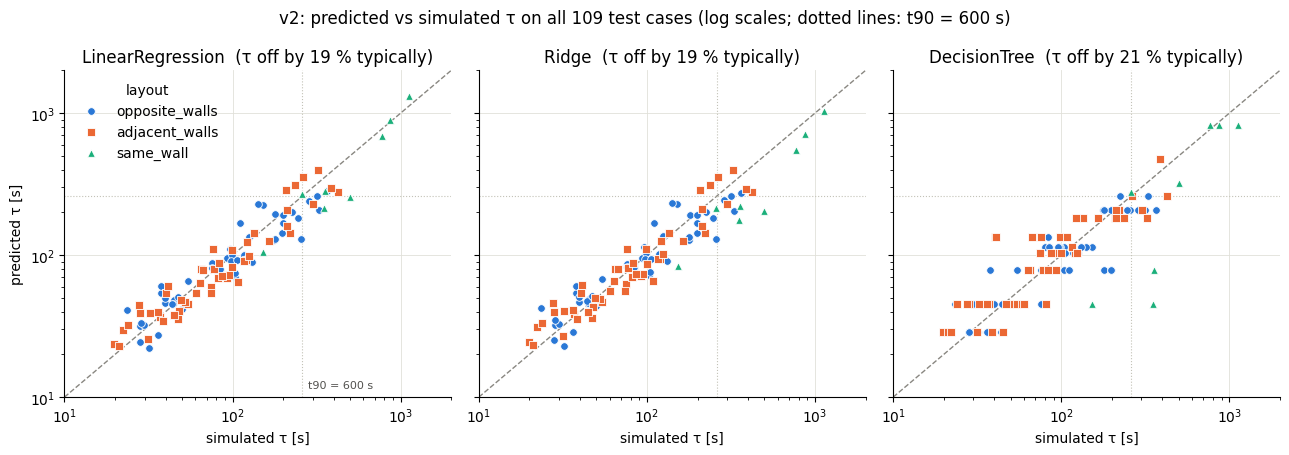

In [12]:
# Colour and marker per layout, the same in every version
LAYOUT_STYLE = {
    "opposite_walls": ("#2a78d6", "o"),
    "adjacent_walls": ("#eb6834", "s"),
    "same_wall": ("#1baf7a", "^"),
}
plot_models = ["LinearRegression", "Ridge", "DecisionTree"]
tau_600 = 600 / LN10  # τ at which t90 = 600 s

low, high = 10, 2000
fig, axes = plt.subplots(1, len(plot_models), figsize=(13, 4.6), sharex=True, sharey=True)
for ax, name in zip(axes, plot_models):
    ax.plot([low, high], [low, high], color="#898781", linewidth=1, linestyle="--", zorder=1)
    ax.axvline(tau_600, color="#c3c2b7", linewidth=0.8, linestyle=":", zorder=1)
    ax.axhline(tau_600, color="#c3c2b7", linewidth=0.8, linestyle=":", zorder=1)
    for layout, (color, marker) in LAYOUT_STYLE.items():
        in_layout = test_df["layout"] == layout
        ax.scatter(
            tau_test[in_layout], tau_pred.loc[in_layout, name],
            s=30, color=color, marker=marker, edgecolor="white", linewidth=0.6,
            label=layout, zorder=2,
        )
    ax.set_title(f"{name}  (τ off by {100 * tau_scores.loc[name, 'median relative error']:.0f} % typically)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_xlabel("simulated τ [s]")
    ax.grid(color="#e1e0d9", linewidth=0.6, which="major")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].text(tau_600 * 1.08, low * 1.15, "t90 = 600 s", color="#52514e", fontsize=8)

axes[0].set_ylabel("predicted τ [s]")
axes[0].legend(title="layout", frameon=False, loc="upper left")
fig.suptitle("v2: predicted vs simulated τ on all 109 test cases (log scales; dotted lines: t90 = 600 s)")
fig.tight_layout()
plt.show()

## 7) What the models learned

As in v1, the linear model works on log(τ), so exp(coefficient) is a factor on τ.

- **Wind speed:** log(τ) is now a straight line in log(wind speed), so τ ∝ (wind speed)^b. The exponent b is the coefficient divided by the standard deviation of log(wind speed). b = −1 would mean: twice the wind, half the τ.
- The other numeric inputs: factor on τ per standard deviation, as in v1.
- The categories: ratios between two categories, with the tilt effect added up from the mode and the hinge column, as in v1.

As before, this is not proof of a physical cause.

In [13]:
feature_names = pipelines["LinearRegression"].named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(pipelines["LinearRegression"].named_steps["model"].coef_, index=feature_names)

wind_scaler = pipelines["LinearRegression"].named_steps["preprocess"].named_transformers_["wind"].named_steps["scale"]
wind_exponent = coefficients["log_wind_speed"] / wind_scaler.scale_[0]
print(f"τ ∝ (wind speed)^{wind_exponent:.2f}: twice the wind speed gives {2 ** wind_exponent:.2f} × τ")

display(pd.DataFrame({
    "standard deviation": X_train[other_num_cols].std(),
    "factor on τ per standard deviation": np.exp(coefficients[other_num_cols]),
}).sort_values("factor on τ per standard deviation").round(2))

c = coefficients
ratios = {
    "adjacent_walls instead of opposite_walls": c["layout_adjacent_walls"] - c["layout_opposite_walls"],
    "same_wall instead of opposite_walls": c["layout_same_wall"] - c["layout_opposite_walls"],
}
for w in ("window1", "window2"):
    turned = c[f"{w}_mode_turn"] + (c[f"{w}_hinge_left"] + c[f"{w}_hinge_right"]) / 2
    tilted = c[f"{w}_mode_tilt"] + c[f"{w}_hinge_none"]
    ratios[f"{w} tilted instead of turned"] = tilted - turned
    ratios[f"{w} hinge right instead of left"] = c[f"{w}_hinge_right"] - c[f"{w}_hinge_left"]
display(np.exp(pd.Series(ratios)).round(2).to_frame("factor on τ"))

importances = pd.Series(pipelines["DecisionTree"].named_steps["model"].feature_importances_, index=feature_names)
display(importances.sort_values(ascending=False).head(8).round(3).to_frame("DecisionTree importance"))
same_tree = np.allclose(t90_pred["DecisionTree"], v1_pred.loc[t90_pred.index, "t90 DecisionTree"], atol=0.1)
print("DecisionTree predictions identical to v1:", same_tree)

τ ∝ (wind speed)^-0.97: twice the wind speed gives 0.51 × τ


,standard deviation,factor on τ per standard deviation
window1_angle_deg,28.20,0.83
window2_angle_deg,28.37,0.88
window2_x_m,0.97,1.00
window1_x_m,1.03,1.08


,factor on τ
adjacent_walls instead of opposite_walls,0.94
same_wall instead of opposite_walls,3.80
window1 tilted instead of turned,1.77
window1 hinge right instead of left,1.07
window2 tilted instead of turned,1.94
window2 hinge right instead of left,0.90


,DecisionTree importance
window2_angle_deg,0.354
window1_angle_deg,0.296
log_wind_speed,0.248
layout_same_wall,0.094
window2_x_m,0.008
window1_hinge_none,0.000
window2_hinge_none,0.000
window2_hinge_left,0.000


DecisionTree predictions identical to v1: True


The decision tree does not change: a tree only compares an input with thresholds ("wind speed < 2.3 m/s?"). The logarithm keeps the order of the values, so the tree finds the same splits, just with log thresholds.

## 8) Save the results

As in v0 and v1: `results/v2_log_wind.csv` holds the t90 scores on the same 93 test cases, `results/v2_log_wind_test_predictions.csv` the predicted t90 and τ of every model for all 109 test cases.

In [14]:
summary = results.drop(columns="lowest prediction [s]").reset_index(names="model")
summary.insert(0, "version", VERSION)
summary["target"] = "log(tau_s)"
summary["n_train"] = len(X_train)
summary["n_test"] = len(y_test_t90)
summary.to_csv(RESULTS_DIR / f"{VERSION}.csv", index=False, float_format="%.3f")

test_predictions = pd.concat([
    test_df[[TARGET_COL, TAU_COL]].add_suffix(" simulated"),
    t90_pred.add_prefix("t90 "),
    tau_pred.add_prefix("tau "),
], axis=1)
test_predictions.to_csv(RESULTS_DIR / f"{VERSION}_test_predictions.csv", index_label="case_id", float_format="%.1f")
display(summary.round(3))

,version,model,MAE [s],RMSE [s],R²,target,n_train,n_test
0,v2_log_wind,Mean value (reference),115.568,142.251,-0.007,log(tau_s),432,93
1,v2_log_wind,LinearRegression,47.322,71.622,0.745,log(tau_s),432,93
2,v2_log_wind,Ridge,47.252,72.828,0.736,log(tau_s),432,93
3,v2_log_wind,DecisionTree,57.922,85.315,0.638,log(tau_s),432,93


## 9) Findings and next version

**Result:** log(wind speed) improves the linear models in every t90 score. LinearRegression: MAE 50 → 47 s, RMSE 76 → 72 s, R² 0.71 → 0.75 (v0: 53 s, 70 s, 0.75). Ridge gives nearly the same. On all 109 test cases, the R² of log(τ) rises from 0.90 to 0.91, and the linear model now recognises 11 of the 16 "t90 > 600 s" cases (v1: 6), still with 2 false alarms among the 93 others.

**Where** (section 6.2): the error drops most at the two ends, for the fastest cases (≤ 100 s: 25 → 21 s) and the slowest (400–600 s: 140 → 118 s). These are the strongest and the weakest winds, where a straight line in the wind speed itself was furthest off. In between it changes little, and the typical relative error of τ even rises slightly (18 → 19 %): v2 mainly reduces the large errors.

**Physics:** the model learns τ ∝ (wind speed)^−0.97, i.e. twice the wind gives about half the τ. This matches the exponent of −0.95 in the data (v0, section 9) and the simple expectation that the airflow through the windows grows in proportion to the wind speed.

**The decision tree** gives exactly the same predictions as in v1, as expected (section 7). Its importances moved from `window1_mode_tilt` to `window1_angle_deg`. Both mean the same thing here, because a tilted window always has 6° and `hinge = none`. Importances of such interchangeable inputs have to be read with care.

**Where the versions stand:** on the 93 test cases with t90, v0's tree is still the most accurate (MAE 42 s, R² 0.81). v2's linear model is close in R² (0.75), covers every case, never gives impossible values, and recognises most "t90 > 600 s" cases.

**Remaining weak points:**

- Slow cases (t90 above 300 s) are still off by about 2 minutes on average.
- The linear model uses one wind exponent for all layouts, but for same-wall windows the data show only about −0.5 (v0, section 9). There are only 8 same-wall test cases, so this cannot be judged well yet.
- The tree still uses the template parameters, which are too coarse for τ (v1).

**Options for the next version (v3):**

1. Choose the model complexity (tree depth, Ridge `alpha`) with cross-validation on the training cases.
2. Try non-linear models on log(τ), e.g. a random forest or gradient boosting. They can learn a different wind effect per layout.
3. For the linear model: an interaction between layout and log(wind speed), so that each layout gets its own wind exponent.